<a href="https://colab.research.google.com/github/rperezen/intro-to-ML/blob/main/Homework_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Problem 1: Cancer Dataset ---
              Model  Accuracy  Precision   Recall
       SVM (Linear)  0.964912      1.000 0.904762
         SVM (Poly)  0.885965      1.000 0.690476
          SVM (RBF)  0.973684      1.000 0.928571
Logistic Regression  0.964912      0.975 0.928571


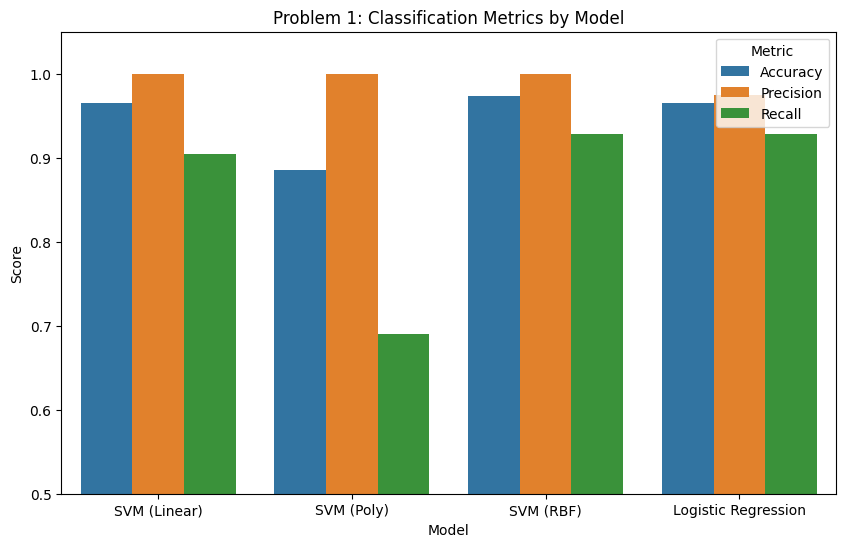


--- Problem 2: US Housing Dataset ---
             Model  R2 Score          MSE
      SVR (Linear)  0.617993 1.930883e+12
        SVR (Poly)  0.541498 2.317529e+12
         SVR (RBF)  0.596951 2.037242e+12
Linear Reg (Ridge)  0.643613 1.801383e+12


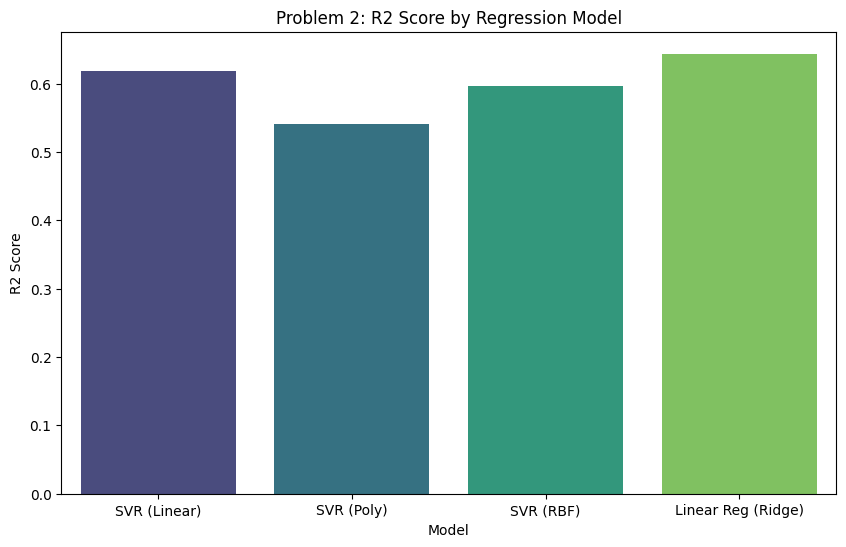

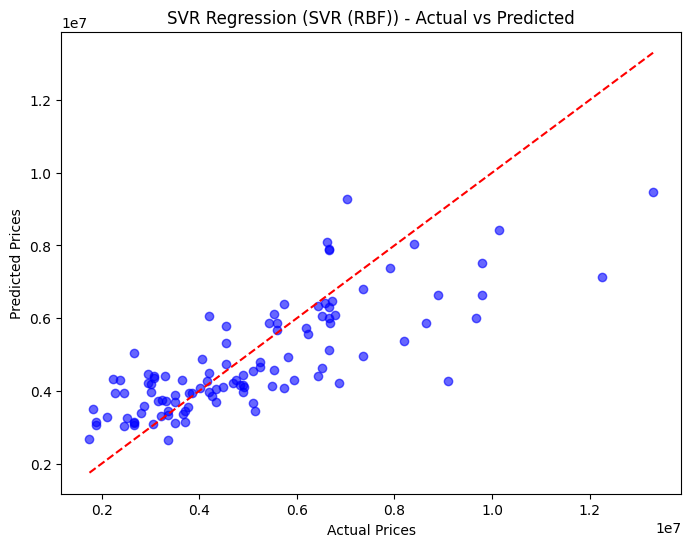

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import accuracy_score, precision_score, recall_score, mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')

def run_problem_1():
    print("--- Problem 1: Cancer Dataset ---")
    # Load Data
    try:
        df = pd.read_csv('Cancer.csv')
    except FileNotFoundError:
        print("Error: 'Cancer.csv' not found. Please upload it to Colab.")
        return

    df = df.drop(['id', 'Unnamed: 32'], axis=1, errors='ignore')

    # Preprocess
    df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})
    X = df.drop('diagnosis', axis=1)
    y = df['diagnosis']

    # Train/Test Split (80/20)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

    # Standardize
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Train SVM models & Logistic Regression
    models = {
        'SVM (Linear)': SVC(kernel='linear', random_state=42),
        'SVM (Poly)': SVC(kernel='poly', random_state=42),
        'SVM (RBF)': SVC(kernel='rbf', random_state=42),
        'Logistic Regression': LogisticRegression(random_state=42)
    }

    results = []
    for name, model in models.items():
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        results.append({
            'Model': name,
            'Accuracy': accuracy_score(y_test, y_pred),
            'Precision': precision_score(y_test, y_pred),
            'Recall': recall_score(y_test, y_pred)
        })

    res_df = pd.DataFrame(results)
    print(res_df.to_string(index=False))

    # Plot classification metrics
    res_df_melted = res_df.melt(id_vars='Model', var_name='Metric', value_name='Score')
    plt.figure(figsize=(10, 6))
    sns.barplot(data=res_df_melted, x='Model', y='Score', hue='Metric')
    plt.title('Problem 1: Classification Metrics by Model')
    plt.ylim(0.5, 1.05)
    plt.show() # This ensures the plot displays in the notebook


def run_problem_2():
    print("\n--- Problem 2: US Housing Dataset ---")
    # Load Data
    try:
        df = pd.read_csv('Housing.csv')
    except FileNotFoundError:
        import urllib.request
        import os
        print("'Housing.csv' not found. Downloading...")
        housing_url = "https://raw.githubusercontent.com/yasserh/housing-prices-dataset/main/Housing.csv"
        urllib.request.urlretrieve(housing_url, "Housing.csv")
        df = pd.read_csv('Housing.csv')

    # Select specific columns from prompt
    features = ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom',
                'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea']

    # Preprocess binary variables
    binary_cols = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
    for col in binary_cols:
        if col in df.columns:
            df[col] = df[col].map({'yes': 1, 'no': 0})

    X = df[features]
    y = df['price']

    # Train/Test Split (80/20)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Standardize Features
    scaler_X = StandardScaler()
    X_train_scaled = scaler_X.fit_transform(X_train)
    X_test_scaled = scaler_X.transform(X_test)

    # Standardize Target (Crucial for SVR convergence on large targets)
    scaler_y = StandardScaler()
    y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1)).ravel()
    y_test_scaled = scaler_y.transform(y_test.values.reshape(-1, 1)).ravel()

    # Train SVR models & Linear Regression with Regularization (Ridge)
    models = {
        'SVR (Linear)': SVR(kernel='linear'),
        'SVR (Poly)': SVR(kernel='poly'),
        'SVR (RBF)': SVR(kernel='rbf'),
        'Linear Reg (Ridge)': Ridge(alpha=1.0)
    }

    results = []
    best_model_name = 'SVR (RBF)'
    best_y_pred = None

    for name, model in models.items():
        model.fit(X_train_scaled, y_train_scaled)
        y_pred_scaled = model.predict(X_test_scaled)

        # Inverse transform to calculate real metrics in standard pricing
        y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()

        results.append({
            'Model': name,
            'R2 Score': r2_score(y_test, y_pred),
            'MSE': mean_squared_error(y_test, y_pred)
        })

        if name == best_model_name:
            best_y_pred = y_pred

    res_df = pd.DataFrame(results)
    print(res_df.to_string(index=False))

    # Plot R2 scores
    plt.figure(figsize=(10, 6))
    sns.barplot(data=res_df, x='Model', y='R2 Score', palette='viridis')
    plt.title('Problem 2: R2 Score by Regression Model')
    plt.show() # This ensures the plot displays in the notebook

    # Plot Actual vs Predicted for the RBF model
    plt.figure(figsize=(8, 6))
    plt.scatter(y_test, best_y_pred, alpha=0.6, color='blue')
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')
    plt.xlabel('Actual Prices')
    plt.ylabel('Predicted Prices')
    plt.title(f'SVR Regression ({best_model_name}) - Actual vs Predicted')
    plt.show() # This ensures the plot displays in the notebook

if __name__ == "__main__":
    run_problem_1()
    run_problem_2()